# Counterfeit banknote detection: walkthrough

This notebook walks through the case study step by step. Every function used here lives in `src/banknote`, so the same results can be reproduced from the terminal with `banknote all`.

**Scenario.** A bank is fitting its ATMs with optical scanners that turn each bill into four image statistics. We need to choose a classifier that catches counterfeits, explain it, fit it into a slow microchip, and keep the human review queue small.

In [1]:
%matplotlib inline
from pathlib import Path

import pandas as pd
from IPython.display import display

from banknote import experiments as ex
from banknote import plots
from banknote.config import ATM_MAX_DEPTH, REVIEW_MARGIN
from banknote.data import load_banknotes, make_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.precision", 4)

## 1. Load and inspect the data

The CSV is downloaded from UCI on first use and cached in `data/raw/`.

In [2]:
df = load_banknotes(ROOT / "data" / "raw")
print(df.shape)
df.head()

(1372, 5)


,variance,skewness,kurtosis,entropy,is_fake
0,3.6216,8.6661,-2.8073,-0.4470,0
1,4.5459,8.1674,-2.4586,-1.4621,0
2,3.8660,-2.6383,1.9242,0.1065,0
3,3.4566,9.5228,-4.0112,-3.5944,0
4,0.3292,-4.4552,4.5718,-0.9888,0


In [3]:
df["is_fake"].value_counts().rename(index={0: "genuine (0)", 1: "counterfeit (1)"})

is_fake
genuine (0)        762
counterfeit (1)    610
Name: count, dtype: int64

The four features already live on different scales, which matters for distance-based models (section 5):

In [4]:
df.drop(columns="is_fake").describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
variance,0.4337,2.8428,-7.0421,6.8248
skewness,1.9224,5.8690,-13.7731,12.9516
kurtosis,1.3976,4.3100,-5.2861,17.9274
entropy,-1.1917,2.1010,-8.5482,2.4495


## 2. Split once, cross-validate on the training set

A stratified 80/20 split keeps the class ratio in both sets. The test set stands in for new bills arriving at the ATM, so it is scored only once per model.

In [5]:
split = make_split(df)
print(
    f"train: {len(split.y_train)} bills | test: {len(split.y_test)} bills "
    f"({int((split.y_test == 0).sum())} genuine, {int(split.y_test.sum())} counterfeit)"
)

train: 1097 bills | test: 275 bills (153 genuine, 122 counterfeit)


## 3. Compare five models

Each model is a `Pipeline` (`StandardScaler` → classifier; the tree is left unscaled), evaluated with stratified 5-fold cross-validation. *Fakes accepted* are false negatives: counterfeits that would enter the ATM.

In [6]:
results = ex.compare_models(split)
cols = [
    "display_name",
    "cv_accuracy_mean",
    "cv_accuracy_std",
    "cv_recall_mean",
    "test_accuracy",
    "fakes_accepted",
    "genuine_rejected",
]
results[cols]

,display_name,cv_accuracy_mean,cv_accuracy_std,cv_recall_mean,test_accuracy,fakes_accepted,genuine_rejected
0,SVM (RBF kernel),1.0000,0.0000,1.0000,1.0000,0,0
1,k-NN (k=5),0.9982,0.0022,1.0000,1.0000,0,0
2,Decision tree,0.9891,0.0062,0.9918,0.9673,1,8
3,Linear SVM,0.9882,0.0046,0.9939,1.0000,0,0
4,Logistic regression,0.9781,0.0067,0.9939,0.9927,0,2


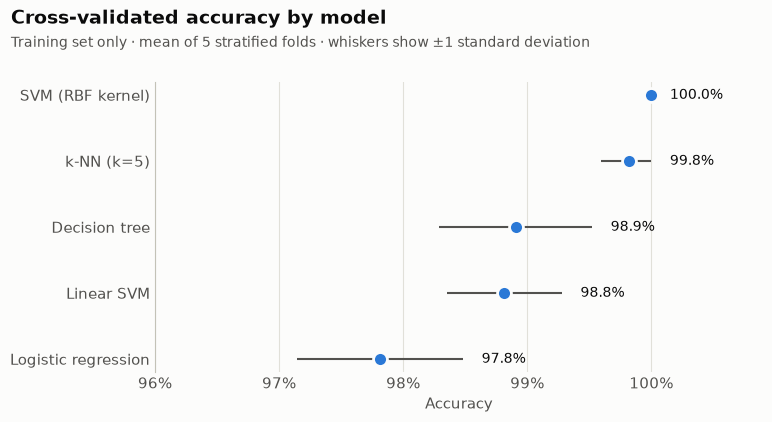

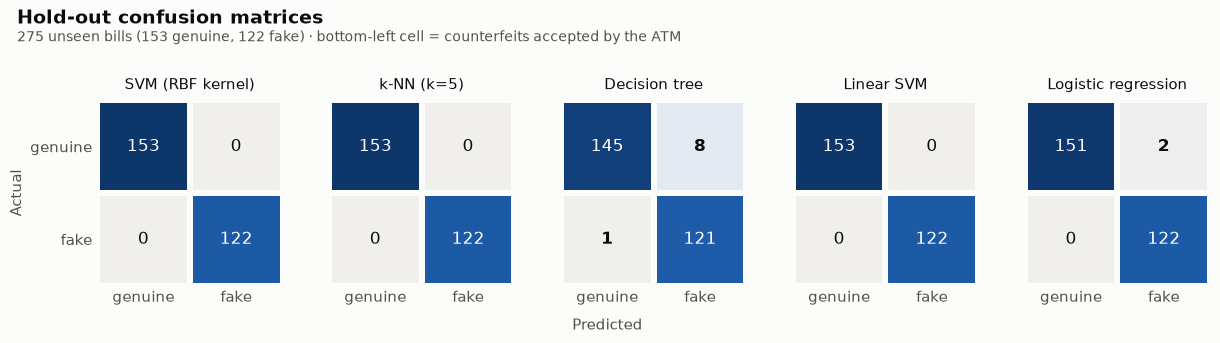

In [7]:
display(plots.plot_model_comparison(results))
display(plots.plot_confusion_matrices(results))

## 4. Explain the baseline

With standardized features, each logistic-regression coefficient is the change in the log-odds of *counterfeit* for a one-standard-deviation increase in that feature.

,feature,coefficient,odds_ratio_per_sd,pushes_towards
0,skewness,-4.6901,0.0092,genuine
1,variance,-4.6839,0.0092,genuine
2,kurtosis,-4.3864,0.0124,genuine
3,entropy,0.2220,1.2486,counterfeit


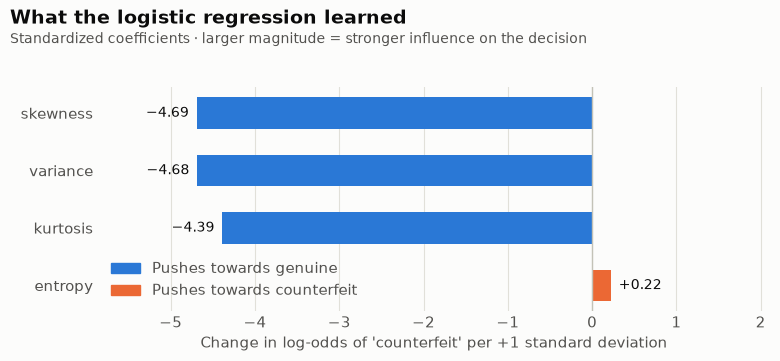

In [8]:
coefs = ex.explain_logistic(split)
display(coefs)
display(plots.plot_logistic_coefficients(coefs))

Higher `variance`, `skewness` and `kurtosis` all push towards *genuine*. A linear model is monotonic, so a counterfeiter who can raise image variance keeps moving towards "genuine" with no upper limit. This is the main weakness of an otherwise accurate, explainable model.

## 5. Fit the model into the ATM chip

The firmware can evaluate at most 4 consecutive IF/THEN checks, which is a decision tree with `max_depth=4`. How much accuracy does that cost?

,max_depth,actual_depth,n_leaves,cv_accuracy_mean,test_accuracy,fakes_accepted,genuine_rejected
0,1,1,2,0.8496,0.8545,10,30
1,2,2,4,0.9070,0.9309,9,10
2,3,3,8,0.9326,0.9491,6,8
3,4,4,12,0.9526,0.9491,7,7
4,5,5,18,0.9717,0.9527,1,12
5,6,6,23,0.9872,0.9636,2,8
6,7,7,26,0.9891,0.9636,2,8
7,8,8,27,0.9891,0.9673,1,8
8,9,8,27,0.9891,0.9673,1,8
9,10,8,27,0.9891,0.9673,1,8


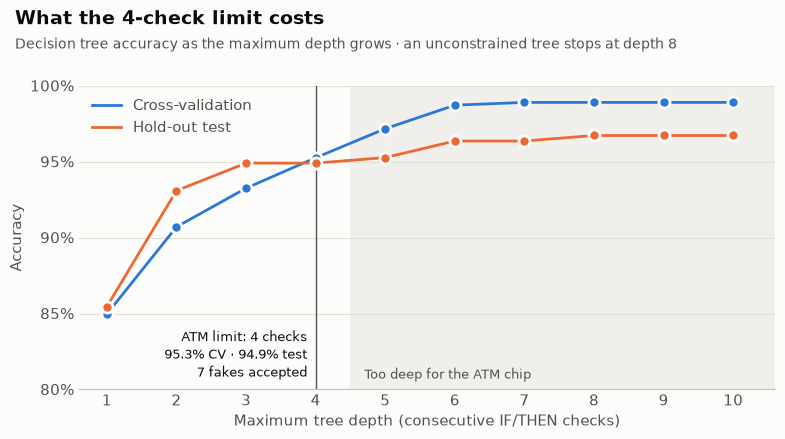

In [9]:
depth = ex.depth_tradeoff(split)
display(
    depth[
        [
            "max_depth",
            "actual_depth",
            "n_leaves",
            "cv_accuracy_mean",
            "test_accuracy",
            "fakes_accepted",
            "genuine_rejected",
        ]
    ]
)
display(plots.plot_depth_tradeoff(depth, ATM_MAX_DEPTH))

The depth-limited tree can be handed to firmware engineers as plain rules, in the camera's own units:

In [10]:
print(ex.atm_rules(split, max_depth=ATM_MAX_DEPTH))

|--- variance <= 0.274
|   |--- skewness <= 7.565
|   |   |--- variance <= -0.459
|   |   |   |--- kurtosis <= 6.216
|   |   |   |   |--- class: counterfeit
|   |   |   |--- kurtosis >  6.216
|   |   |   |   |--- class: counterfeit
|   |   |--- variance >  -0.459
|   |   |   |--- kurtosis <= 0.441
|   |   |   |   |--- class: counterfeit
|   |   |   |--- kurtosis >  0.441
|   |   |   |   |--- class: genuine
|   |--- skewness >  7.565
|   |   |--- variance <= -4.726
|   |   |   |--- class: counterfeit
|   |   |--- variance >  -4.726
|   |   |   |--- class: genuine
|--- variance >  0.274
|   |--- kurtosis <= -4.386
|   |   |--- variance <= 3.304
|   |   |   |--- class: counterfeit
|   |   |--- variance >  3.304
|   |   |   |--- class: genuine
|   |--- kurtosis >  -4.386
|   |   |--- variance <= 1.596
|   |   |   |--- kurtosis <= -2.252
|   |   |   |   |--- class: counterfeit
|   |   |   |--- kurtosis >  -2.252
|   |   |   |   |--- class: genuine
|   |   |--- variance >  1.596
|   |   |   

## 6. Why scaling matters for k-NN

Add a feature with no signal but a huge range (daily ATM volume, 10,000 to 80,000) and compare k-NN with and without standardization.

,feature_set,scaling,cv_accuracy_mean,test_accuracy,fakes_accepted
0,4 sensor features,unscaled,0.9991,1.0000,0
1,4 sensor features,scaled,0.9982,1.0000,0
2,+ ATM volume,unscaled,0.5205,0.5055,71
3,+ ATM volume,scaled,0.9945,0.9927,1


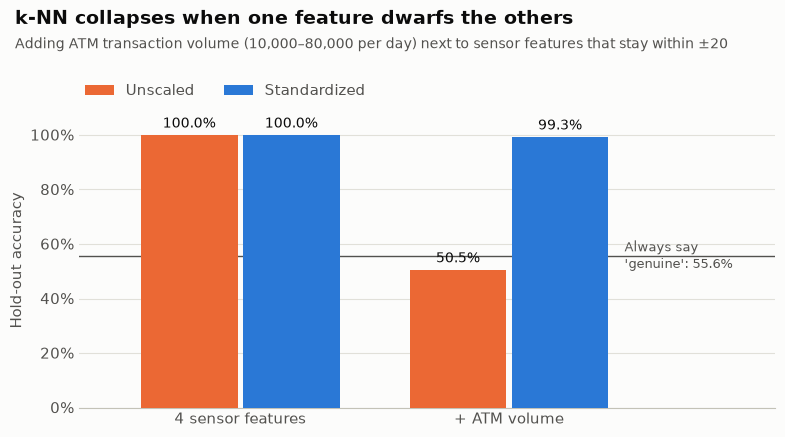

In [11]:
scaling = ex.scaling_experiment(split)
display(scaling)
majority = float((split.y_test == 0).mean())
display(plots.plot_scaling(scaling, majority))

Unscaled, Euclidean distance is dominated by volume, so k-NN ends up comparing ATMs instead of bills and does worse than always answering "genuine".

## 7. Send only the borderline bills to a human

A linear SVM's decision function is a signed distance from the boundary. Bills inside the margin are the ones the model is least sure about.

15 of 275 bills need a human (5.5%)


,bill_id,variance,skewness,kurtosis,entropy,decision_value,predicted,actual,correct
0,942,-3.3793,-13.7731,17.9274,-2.0323,0.0597,counterfeit,counterfeit,True
1,248,0.3798,0.7098,0.7572,-0.4444,-0.0739,genuine,genuine,True
2,925,1.7425,3.6833,-4.0129,-1.7207,0.1311,counterfeit,counterfeit,True
3,226,0.5706,-0.0248,1.2421,-0.5621,-0.1677,genuine,genuine,True
4,917,1.5631,0.8960,-1.9702,0.6547,0.4205,counterfeit,counterfeit,True
5,1059,-3.2305,-7.2135,11.6433,-0.9461,0.4545,counterfeit,counterfeit,True
6,47,-0.7869,9.5663,-3.7867,-7.5034,-0.6489,genuine,genuine,True
7,119,0.9297,-3.7971,4.6429,-0.2957,-0.6556,genuine,genuine,True
8,885,0.0302,-1.0512,1.4024,0.7737,0.6937,counterfeit,counterfeit,True
9,227,-2.6479,10.1374,-1.3310,-5.4707,-0.7808,genuine,genuine,True


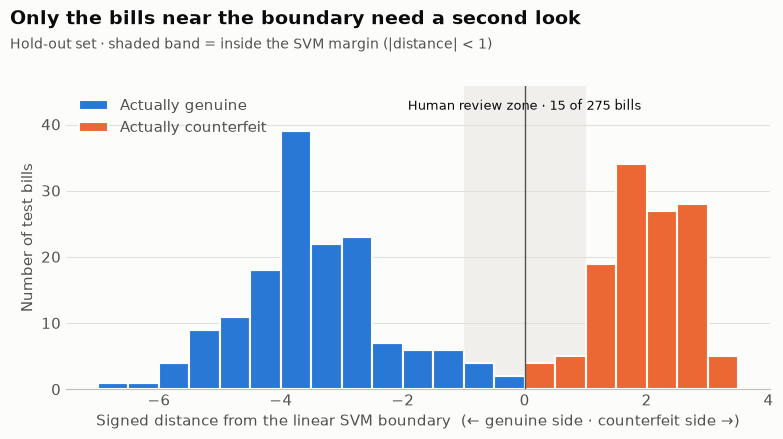

In [12]:
decisions = ex.svm_decision_values(split)
review = ex.borderline_bills(decisions, REVIEW_MARGIN)
print(f"{len(review)} of {len(decisions)} bills need a human ({len(review) / len(decisions):.1%})")
display(review.head(10))
display(plots.plot_decision_values(decisions, REVIEW_MARGIN))

## Takeaways

- Every model separates these bills well; an RBF-kernel SVM was perfect in cross-validation.
- The 4-check limit lets 7 of 122 test counterfeits through. One more check brings that down to 1, at the cost of more genuine bills rejected.
- A linear model needs only four multiplications and a comparison, missed no counterfeits on the test set, and is worth proposing to the firmware team. It needs range checks to resist gaming.
- Always standardize inside the pipeline before using distance-based models.
- The SVM margin cuts the human review queue to about 5% of bills.